# Construcción de variables
## Efecto del salario mínimo en el desempleo en Chile: jóvenes (15–24) vs. adultos (25+)

Este notebook toma los archivos descargados de las fuentes oficiales (carpeta `datos_originales/`) y construye todas las variables del modelo, guardando dos bases en `datos_procesados/`:

| Archivo | Contenido | Uso |
|---|---|---|
| `base_trimestral.csv` | Una fila por trimestre (2010-T1 a 2026-T3) | Regresiones separadas por grupo, gráficos, estadística descriptiva |
| `base_apilada.csv` | Dos filas por trimestre (jóvenes y adultos) | Modelo principal con interacción |

**Decisiones generales**

- **Frecuencia trimestral calendario (EFM, AMJ, JAS, OND).** La ENE publica trimestres *móviles*, que se solapan y generan autocorrelación artificial en los residuos. Usar solo los trimestres calendario elimina ese solapamiento y los alinea con las cuentas nacionales. La ENE comienza en enero–marzo 2010, por lo que la muestra es **2010-T1 a 2026-T3 (67 trimestres)**.
- **Las series mensuales (salario mínimo, remuneraciones, IPC, Imacec) se promedian dentro de cada trimestre**, para que coincidan con el periodo de referencia de la ENE.

In [1]:
# Si es la primera vez, instala las librerías (luego reinicia el kernel y comenta esta línea):
# %pip install pandas numpy matplotlib statsmodels openpyxl python-calamine

In [2]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt
from statsmodels.tsa.filters.hp_filter import hpfilter

RAW = "datos_originales"
OUT = "datos_procesados"
os.makedirs(OUT, exist_ok=True)

def a_trimestre(fecha):
    # Convierte una fecha mensual al trimestre calendario (año, q)
    return fecha.dt.year, (fecha.dt.month - 1) // 3 + 1

---
## 1. Variables dependientes: desempleo, ocupación y participación por edad (INE, ENE)

**Fuente:** INE, Encuesta Nacional de Empleo, *Indicadores principales de empleo por tramo etario*, series trimestrales vigentes (archivo `indicadores_principales_edad.xlsx`).

**Construcción**
- **Jóvenes:** tramo 15–24 tal como lo publica el INE.
- **Adultos (25+):** se **suman los niveles** (desocupados, ocupados, fuerza de trabajo, población en edad de trabajar) de los tramos 25–34, 35–44, 45–54, 55–64 y 65+, y *luego* se calculan las tasas. No se promedian tasas, porque cada tramo tiene un tamaño distinto y el promedio simple estaría sesgado.
- **Adultos 25–54:** alternativa para robustez, que excluye a los grupos cercanos a la jubilación.

**Definiciones (INE)**
- Tasa de desocupación: $u = \frac{\text{desocupados}}{\text{fuerza de trabajo}}\times 100$ → **variable dependiente principal (H1 y H2)**.
- Tasa de ocupación: $o = \frac{\text{ocupados}}{\text{población en edad de trabajar}}\times 100$ → **robustez**. La literatura prefiere la tasa de empleo porque un alza del salario mínimo puede sacar a jóvenes de la fuerza de trabajo, lo que *atenúa* el efecto en la tasa de desocupación (Brown, Gilroy y Kohen, 1983).
- Tasa de participación: $p = \frac{\text{fuerza de trabajo}}{\text{población en edad de trabajar}}\times 100$ → **solo descriptiva**. No se usa como control porque forma parte de la definición del desempleo.

In [3]:
f = f"{RAW}/indicadores_principales_edad.xlsx"
hojas = ['15-24','25-34','35-44','45-54','55-64','65-Más']
# En cada hoja los valores están en columnas alternadas (nota | valor)
cols = {'pet':3, 'ft':5, 'ocu':7, 'des':9}
trim_cal = {'Ene - Mar':1, 'Abr - Jun':2, 'Jul - Sep':3, 'Oct - Dic':4}

niveles = {}
for h in hojas:
    raw = pd.read_excel(f, sheet_name=h, header=None, skiprows=7)
    raw = raw[pd.to_numeric(raw[0], errors='coerce').notna()]        # solo filas con año
    d = pd.DataFrame({'anio': raw[0].astype(float).astype(int),
                      'trim': raw[1].astype(str).str.strip()})
    for k, c in cols.items():
        d[k] = raw[c].astype(float).values
    d = d[d.trim.isin(trim_cal)].assign(q=lambda x: x.trim.map(trim_cal))
    niveles[h] = d.set_index(['anio','q'])[list(cols)]

def tasas(grupo_hojas, sufijo):
    s = sum(niveles[h] for h in grupo_hojas)
    return pd.DataFrame({f'u_{sufijo}': s.des/s.ft*100,
                         f'o_{sufijo}': s.ocu/s.pet*100,
                         f'p_{sufijo}': s.ft/s.pet*100})

ene = pd.concat([tasas(['15-24'],'15_24'),
                 tasas(['25-34','35-44','45-54','55-64','65-Más'],'25mas'),
                 tasas(['25-34','35-44','45-54'],'25_54')], axis=1)
print(ene.shape)
ene.round(2).head()

(67, 9)


u_15_24  o_15_24  p_15_24  u_25mas  o_25mas  p_25mas  u_25_54  \
anio q                                                                  
2010 1    20.22    30.97    38.82     7.41    60.58    65.44     8.11   
     2    18.80    29.62    36.47     7.10    61.30    65.99     7.73   
     3    17.78    30.49    37.09     6.64    62.38    66.81     7.21   
     4    17.54    31.10    37.71     5.62    63.65    67.44     6.17   
2011 1    16.88    33.20    39.94     6.03    63.26    67.32     6.55   

        o_25_54  p_25_54  
anio q                    
2010 1    70.92    77.18  
     2    71.74    77.75  
     3    72.66    78.31  
     4    73.94    78.81  
2011 1    73.75    78.92

---
## 2. Salario mínimo (Ingreso Mínimo Mensual, IMM)

**Fuente:** leyes de reajuste del Ingreso Mínimo Mensual para trabajadores de 18 a 65 años (Leyes 20.359 a 21.830), compiladas en la hoja `Leyes` de `salario_minimo_chile_2010_2026.xlsx`.

**Construcción**
1. Se arma una serie **mensual** con el monto vigente en cada mes (el último reajuste cuya fecha de vigencia es anterior o igual al mes).
2. Se **promedia por trimestre**. Cuando un reajuste entra en vigor a mitad de trimestre, el promedio lo pondera por los meses en que estuvo vigente (por ejemplo, el alza de agosto 2013 deja el 2013-T3 en $204.333).

El IMM nominal **no entra directamente** al modelo; se usa para construir el índice de Kaitz (sección 3) y el salario mínimo real (sección 4).

In [4]:
leyes = pd.read_excel(f"{RAW}/salario_minimo_chile_2010_2026.xlsx", sheet_name='Leyes')
leyes = leyes.iloc[:, :3].dropna(subset=[leyes.columns[1]])
leyes.columns = ['vigencia','imm','ley']
leyes['vigencia'] = pd.to_datetime(leyes['vigencia'])
leyes = leyes.sort_values('vigencia')

meses = pd.DataFrame({'fecha': pd.date_range('2010-01-01', '2026-09-01', freq='MS')})
imm_m = pd.merge_asof(meses, leyes[['vigencia','imm']], left_on='fecha', right_on='vigencia')
imm_m['anio'], imm_m['q'] = a_trimestre(imm_m.fecha)
imm = imm_m.groupby(['anio','q'])['imm'].mean()
imm.tail(10)

anio  q
2024  2    460000.000000
      3    500000.000000
      4    500000.000000
2025  1    510636.000000
      2    522878.666667
      3    529000.000000
      4    529000.000000
2026  1    539000.000000
      2    548702.000000
      3    553553.000000
Name: imm, dtype: float64

---
## 3. Variable explicativa principal: índice de Kaitz

**Fuente del denominador:** INE, *Índice Nominal de Remuneraciones (IR), serie empalmada*, base anual 2023=100, hoja `General` de `tabulado_ir_empalmado.xlsx`. Se usa la serie **nominal** (el IMM también es nominal, por lo que la inflación se cancela en el cociente) y **sin desestacionalizar** (la estacionalidad se controla con dummies trimestrales, y no corresponde mezclar en un cociente una serie ajustada con otra que no lo está).

**Definición.** El índice de Kaitz mide el salario mínimo *relativo* al salario promedio:
$$\text{Kaitz}_t = \frac{\text{IMM}_t}{\text{Salario promedio}_t}$$

Es la medida estándar de la literatura (Brown, Gilroy y Kohen, 1982, 1983; Neumark y Wascher, 2004), porque captura cuánto "muerde" el mínimo en la distribución salarial: un mismo monto pesa más cuando los salarios son bajos. Además evita que la variable explicativa sea solo una tendencia creciente.

**Por qué el índice de remuneraciones sirve aunque no esté en pesos.** El IR es un índice, es decir, proporcional al salario promedio: $\text{IR}_t = k \cdot \bar w_t$. Entonces:
$$\ln(\text{IMM}_t) - \ln(\text{IR}_t) = \ln \text{Kaitz}_t - \ln k$$
La diferencia con el Kaitz verdadero es una **constante**, que queda absorbida en el intercepto. El coeficiente estimado es exactamente el mismo. En el informe se puede reportar `kaitz_idx` como "índice de Kaitz (2023=100)".

**Variables creadas**
- `ln_kaitz` = ln(IMM) − ln(IR) → **variable explicativa principal**.
- `ln_kaitz_c` = `ln_kaitz` menos su media → versión **centrada** para construir la interacción. Centrar no cambia la interpretación del efecto, pero reduce la colinealidad artificial entre `ln_kaitz`, `d_joven` y su producto (que inflaría los VIF).
- `ln_kaitz_l1`, `ln_kaitz_l2` → rezagos de uno y dos trimestres (**robustez**): el efecto del salario mínimo en el empleo puede tardar en materializarse.

In [5]:
ir_raw = pd.read_excel(f"{RAW}/tabulado_ir_empalmado.xlsx", sheet_name='General', engine='calamine')
ir_raw = ir_raw[pd.to_numeric(ir_raw['año'], errors='coerce').notna()]
ir_m = pd.DataFrame({'anio': ir_raw['año'].astype(int), 'mes': ir_raw['mes'].astype(int),
                     'ir': ir_raw['índice'].astype(float)})
ir_m = ir_m[(ir_m.anio >= 2010)]
ir_m['q'] = (ir_m.mes - 1)//3 + 1
ir = ir_m.groupby(['anio','q'])['ir'].mean()

kaitz = pd.DataFrame({'imm': imm, 'ir': ir})
kaitz['ln_imm']   = np.log(kaitz.imm)
kaitz['ln_kaitz'] = np.log(kaitz.imm) - np.log(kaitz.ir)
# Índice de Kaitz normalizado: promedio 2023 = 100 (solo para gráficos y tablas)
base23 = (kaitz.imm/kaitz.ir).loc[2023].mean()
kaitz['kaitz_idx'] = (kaitz.imm/kaitz.ir) / base23 * 100
kaitz.round(3).tail(8)

imm       ir  ln_imm  ln_kaitz  kaitz_idx
anio q                                                  
2024 4  500000.000  110.406  13.122     8.418    103.955
2025 1  510636.000  113.063  13.143     8.415    103.671
     2  522878.667  114.355  13.167     8.428    104.958
     3  529000.000  115.881  13.179     8.426    104.788
     4  529000.000  117.032  13.179     8.416    103.758
2026 1  539000.000  118.743  13.197     8.421    104.195
     2  548702.000  122.267  13.215     8.409    103.014
     3  553553.000  124.901  13.224     8.397    101.733

---
## 4. Salario mínimo real (robustez)

**Fuente:** IPC general, serie empalmada desde diciembre de 2009, base 2023=100 (INE vía Banco Central, `IPC_EMP_2023.xlsx`).

$$\text{SM real}_t = \frac{\text{IMM}_t}{\text{IPC}_t}\times 100 \quad (\text{pesos de 2023})$$

Se usa como **medida alternativa** del salario mínimo para mostrar que el resultado no depende de usar el Kaitz. La pauta del curso exige expresar las variables monetarias en términos reales.

In [6]:
ipc_raw = pd.read_excel(f"{RAW}/IPC_EMP_2023.xlsx", sheet_name=0, skiprows=2)
ipc_raw.columns = ['fecha','ipc']
ipc_raw = ipc_raw.dropna()
ipc_raw['fecha'] = pd.to_datetime(ipc_raw['fecha'])
ipc_raw = ipc_raw[(ipc_raw.fecha >= '2010-01-01') & (ipc_raw.fecha <= '2026-09-01')]
ipc_raw['anio'], ipc_raw['q'] = a_trimestre(ipc_raw.fecha)
ipc = ipc_raw.groupby(['anio','q'])['ipc'].mean()

real = pd.DataFrame({'ipc': ipc})
real['sm_real']    = imm / ipc * 100
real['ln_sm_real'] = np.log(real.sm_real)
real.round(2).tail(5)

ipc    sm_real  ln_sm_real
anio q                               
2025 3  108.81  486183.44       13.09
     4  109.31  483959.50       13.09
2026 1  110.05  489762.54       13.10
     2  112.30  488603.74       13.10
     3  113.06  489595.51       13.10

---
## 5. Controles macroeconómicos

### 5.1 Inflación

**Fuentes:**
- 2011–2026: IPC, variación en 12 meses, **serie empalmada** base 2023=100 (`IPC_VAREMP_2023.xlsx`). Es consistente con el índice de IPC usado para deflactar el salario mínimo.
- 2010: IPC General, variación en 12 meses, **información histórica** (`IPC_VAR_ANUAL_HIST_NEW.xlsx`). La serie empalmada parte en diciembre de 2009, así que no puede calcular la variación en 12 meses de 2010. La serie histórica sí la trae, con la cifra oficial publicada en su momento.

**Por qué se combinan así.** Ambas series coinciden en todos los meses, excepto 22 meses entre 2014 y 2019, donde difieren hasta 0,7 puntos porcentuales por los cambios de base del IPC (2013 y 2018). Por eso la serie histórica se usa **solo para completar 2010** y la empalmada para el resto. En el informe basta una nota: "inflación de 2010 tomada de la serie histórica del Banco Central, por no estar disponible en la serie empalmada".

Se promedia la variación mensual en 12 meses dentro de cada trimestre.

**Justificación:** controla por el entorno nominal de la economía. Los periodos de alta inflación (como 2022) coinciden con reajustes grandes del salario mínimo y con cambios en el mercado laboral, así que omitirla podría sesgar el coeficiente del Kaitz.

In [7]:
def leer_bcch(archivo, nombre):
    d = pd.read_excel(f"{RAW}/{archivo}", sheet_name=0, skiprows=2)
    d.columns = ['fecha', nombre]
    d = d.dropna()
    d['fecha'] = pd.to_datetime(d['fecha'])
    return d.set_index('fecha')[nombre]

inf_emp  = leer_bcch("IPC_VAREMP_2023.xlsx", "inflacion")          # oficial empalmada, desde 2011
inf_hist = leer_bcch("IPC_VAR_ANUAL_HIST_NEW.xlsx", "inflacion")   # histórica, se usa solo para 2010
inf_m = pd.concat([inf_hist.loc['2010-01-01':'2010-12-01'], inf_emp]).sort_index()
inf_m = inf_m[~inf_m.index.duplicated(keep='last')].loc[:'2026-09-01']

inf_m = inf_m.to_frame()
inf_m['anio'], inf_m['q'] = inf_m.index.year, (inf_m.index.month - 1)//3 + 1
inflacion = inf_m.groupby(['anio','q'])['inflacion'].mean()

faltan = [f"{a}-T{q}" for (a,q) in ene.index if (a,q) not in inflacion.index]
print("Trimestres sin dato de inflación:", faltan if faltan else "ninguno ✔")
print(inflacion.loc[2010].round(2))

Trimestres sin dato de inflación: ninguno ✔
q
1   -0.23
2    1.20
3    2.27
4    2.50
Name: inflacion, dtype: float64


### 5.2 Actividad económica: Imacec, variación anual

**Fuente:** Banco Central, *Imacec empalmado, serie original* (índice 2018=100), `CCNN2018_IMACEC_01_A.xlsx`.

**Construcción:** se promedia el índice mensual en cada trimestre y se calcula la variación respecto del **mismo trimestre del año anterior**:
$$\text{imacec\_va}_t = \left(\frac{\overline{\text{Imacec}}_t}{\overline{\text{Imacec}}_{t-4}} - 1\right)\times 100$$
Comparar con el mismo trimestre del año anterior elimina la estacionalidad, por eso se usa la serie *original* y no la desestacionalizada. Por eso también se descargó desde 2009: para calcular la variación de 2010.

**Justificación:** es el **control del ciclo económico**. El desempleo sube en recesiones por razones que no tienen que ver con el salario mínimo; sin este control, el coeficiente del Kaitz podría estar capturando el ciclo. Se prefiere al desempleo adulto (usado en estudios de EE.UU.) porque aquí los adultos son el **grupo de comparación**.

In [8]:
im_raw = pd.read_excel(f"{RAW}/CCNN2018_IMACEC_01_A.xlsx", sheet_name=0, skiprows=2)
im_raw.columns = ['fecha','imacec']
im_raw = im_raw.dropna()
im_raw['fecha'] = pd.to_datetime(im_raw['fecha'])
im_raw['anio'], im_raw['q'] = a_trimestre(im_raw.fecha)
im_q = im_raw.groupby(['anio','q'])['imacec'].mean().sort_index()
imacec_va = (im_q / im_q.shift(4) - 1) * 100
act = pd.DataFrame({'imacec': im_q, 'imacec_va': imacec_va})
act.loc[(2020,1):(2021,4)].round(2)

imacec  imacec_va
anio q                   
2020 1   99.18      -0.40
     2   86.80     -15.02
     3   89.14      -9.25
     4  102.74       0.10
2021 1   99.61       0.43
     2  102.75      18.38
     3  103.62      16.24
     4  114.72      11.67

### 5.3 Brecha de actividad estimada con filtro HP (opcional, robustez)

El IPoM de septiembre 2026 no publica una serie histórica de brecha que cubra todo el periodo, así que se **aproxima**:
1. Se toma el logaritmo del Imacec trimestral y se le quita la estacionalidad (regresión sobre dummies trimestrales).
2. Se aplica el **filtro de Hodrick-Prescott** con λ = 1.600 (valor estándar para datos trimestrales) para obtener la tendencia.
3. Brecha = (ln Imacec ajustado − tendencia) × 100, en % del nivel tendencial.

**Limitaciones a declarar en el informe:** el filtro HP es menos preciso en los extremos de la muestra (sesgo de punta) y es una aproximación estadística, no la brecha que estima el Banco Central. Por eso se usa solo en la robustez; el control principal es `imacec_va`.

In [9]:
im_s = np.log(im_q.loc[(2009,1):(2026,3)])
dq = pd.get_dummies(im_s.index.get_level_values('q'), prefix='q', drop_first=True).astype(float).values
X = np.column_stack([np.ones(len(im_s)), dq])
beta = np.linalg.lstsq(X, im_s.values, rcond=None)[0]
im_sa = im_s.values - dq @ beta[1:]                     # ln Imacec sin estacionalidad
ciclo, tendencia = hpfilter(im_sa, lamb=1600)
act['brecha_hp'] = pd.Series(ciclo*100, index=im_s.index)
act['brecha_hp'].loc[2019:2021].round(2)

anio  q
2019  1     2.42
      2     3.32
      3     1.83
      4    -2.37
2020  1     0.60
      2   -14.48
      3    -9.51
      4    -4.06
2021  1    -0.93
      2     0.29
      3     3.30
      4     4.65
Name: brecha_hp, dtype: float64

---
## 6. Variables binarias y tendencia

| Variable | Definición | Justificación |
|---|---|---|
| `covid` | 1 entre 2020-T2 y 2021-T2 | Recoge el *shock* de la pandemia (cierres, caída abrupta del empleo y recuperación) que no se relaciona con el salario mínimo. El periodo cubre desde el primer trimestre completo con confinamientos hasta la reapertura generalizada; si cambias el rango, justifícalo en el informe. |
| `q1`, `q2`, `q3` | Dummies del trimestre (T4 es la base) | El desempleo y el Imacec tienen estacionalidad (por ejemplo, el empleo agrícola en verano). Se trabaja con series sin desestacionalizar y se controla con dummies, que es lo más transparente. |
| `tendencia` | 1, 2, …, 67 | Las tasas pueden tener tendencias de largo plazo (por ejemplo, la caída de la participación juvenil, asociada a más años de estudio). Se incluye si el test ADF indica que las series no son estacionarias. |

In [10]:
base = pd.concat([ene, kaitz, real, inflacion.rename('inflacion'),
                  act[['imacec','imacec_va','brecha_hp']]], axis=1).sort_index().loc[(2010,1):(2026,3)]
idx = base.index
base['covid']     = [int((2020,2) <= t <= (2021,2)) for t in idx]
for k in (1,2,3):
    base[f'q{k}'] = (idx.get_level_values('q') == k).astype(int)
base['tendencia'] = np.arange(1, len(base)+1)

# Rezagos y versión centrada del Kaitz
base['ln_kaitz_l1'] = base['ln_kaitz'].shift(1)
base['ln_kaitz_l2'] = base['ln_kaitz'].shift(2)
base['ln_kaitz_c']  = base['ln_kaitz'] - base['ln_kaitz'].mean()

base = base.reset_index()
base.insert(0, 'trimestre', base.anio.astype(str) + '-T' + base.q.astype(str))
print(base.shape)
base.round(3).head()

(67, 32)


,trimestre,anio,q,u_15_24,o_15_24,p_15_24,u_25mas,o_25mas,p_25mas,u_25_54,...,imacec_va,brecha_hp,covid,q1,q2,q3,tendencia,ln_kaitz_l1,ln_kaitz_l2,ln_kaitz_c
0,2010-T1,2010,1,20.216,30.973,38.821,7.414,60.584,65.436,8.114,...,1.933,-2.920,0,1,0,0,1,NaN,NaN,-0.090
1,2010-T2,2010,2,18.800,29.616,36.473,7.100,61.302,65.987,7.728,...,6.413,0.399,0,0,1,0,2,8.185,NaN,-0.103
2,2010-T3,2010,3,17.782,30.494,37.089,6.641,62.377,66.814,7.208,...,7.500,-0.237,0,0,0,1,3,8.171,8.185,-0.075
3,2010-T4,2010,4,17.536,31.101,37.715,5.618,63.652,67.441,6.175,...,7.450,-0.670,0,0,0,0,4,8.199,8.171,-0.088
4,2011-T1,2011,1,16.881,33.201,39.944,6.026,63.263,67.319,6.551,...,8.766,0.357,0,1,0,0,5,8.186,8.199,-0.106


---
## 7. Base apilada para el modelo con interacción

El modelo principal estima ambos grupos en una sola ecuación (Neumark y Wascher, 2004; Brown et al., 1983):
$$u_{g,t} = \beta_0 + \beta_1 \ln \text{Kaitz}^c_t + \beta_2 D^{joven}_g + \beta_3(\ln \text{Kaitz}^c_t \times D^{joven}_g) + \beta_4\, \text{imacec\_va}_t + \beta_5\, \pi_t + \delta\, \text{COVID}_t + \textstyle\sum_s \gamma_s Q_s + \varepsilon_{g,t}$$

- Cada trimestre aparece **dos veces**: una fila para jóvenes (`d_joven = 1`) y otra para adultos 25+ (`d_joven = 0`).
- $\beta_1$ = efecto del Kaitz en adultos; $\beta_1+\beta_3$ = efecto en jóvenes; **$\beta_3$ prueba H2**.
- Se incluyen también `o` (ocupación) y `p` (participación) del grupo correspondiente, para la robustez con la tasa de ocupación.
- **Al estimar:** como los dos grupos comparten los mismos trimestres, usa errores estándar robustos (Newey-West) para no subestimar la incertidumbre.

In [11]:
comunes = ['trimestre','anio','q','ln_kaitz','ln_kaitz_c','ln_kaitz_l1','ln_kaitz_l2','kaitz_idx',
           'ln_sm_real','inflacion','imacec_va','brecha_hp','covid','q1','q2','q3','tendencia']
jov = base[comunes].assign(grupo='15-24', d_joven=1, u=base.u_15_24, o=base.o_15_24, p=base.p_15_24)
adu = base[comunes].assign(grupo='25+',   d_joven=0, u=base.u_25mas, o=base.o_25mas, p=base.p_25mas)
apilada = pd.concat([jov, adu]).sort_values(['anio','q','d_joven'], ascending=[True,True,False])
apilada['kaitz_x_joven'] = apilada['ln_kaitz_c'] * apilada['d_joven']
apilada = apilada.reset_index(drop=True)
print(apilada.shape)
apilada.head(4).round(3)

(134, 23)


,trimestre,anio,q,ln_kaitz,ln_kaitz_c,ln_kaitz_l1,ln_kaitz_l2,kaitz_idx,ln_sm_real,inflacion,...,q1,q2,q3,tendencia,grupo,d_joven,u,o,p,kaitz_x_joven
0,2010-T1,2010,1,8.185,-0.090,NaN,NaN,82.296,12.563,-0.233,...,1,0,0,1,15-24,1,20.216,30.973,38.821,-0.090
1,2010-T1,2010,1,8.185,-0.090,NaN,NaN,82.296,12.563,-0.233,...,1,0,0,1,25+,0,7.414,60.584,65.436,-0.000
2,2010-T2,2010,2,8.171,-0.103,8.185,NaN,81.208,12.554,1.200,...,0,1,0,2,15-24,1,18.800,29.616,36.473,-0.103
3,2010-T2,2010,2,8.171,-0.103,8.185,NaN,81.208,12.554,1.200,...,0,1,0,2,25+,0,7.100,61.302,65.987,-0.000


---
## 8. Revisión rápida y exportación

Antes de estimar, revisa: (i) que no haya valores faltantes en las variables del modelo principal, (ii) la tabla de estadística descriptiva (va en la sección de Datos del informe) y (iii) el gráfico de las series.

In [12]:
principales = ['u_15_24','u_25mas','o_15_24','o_25mas','ln_kaitz','kaitz_idx','ln_sm_real','inflacion','imacec_va']
print("Valores faltantes por variable:")
print(base[principales].isna().sum().to_string())
desc = base[['u_15_24','u_25mas','o_15_24','o_25mas','kaitz_idx','sm_real','inflacion','imacec_va']].describe().T
desc[['mean','std','min','max']].round(2) 

Valores faltantes por variable:
u_15_24       0
u_25mas       0
o_15_24       0
o_25mas       0
ln_kaitz      0
kaitz_idx     0
ln_sm_real    0
inflacion     0
imacec_va     0


,mean,std,min,max
u_15_24,18.70,3.01,14.43,27.89
u_25mas,6.54,1.43,4.25,11.22
o_15_24,26.92,4.19,15.76,33.20
o_25mas,62.99,2.77,51.77,65.89
kaitz_idx,90.33,7.82,79.84,105.10
sm_real,376349.75,62178.92,283359.09,489762.54
inflacion,4.03,2.61,-0.23,13.63
imacec_va,2.79,4.49,-15.02,18.38


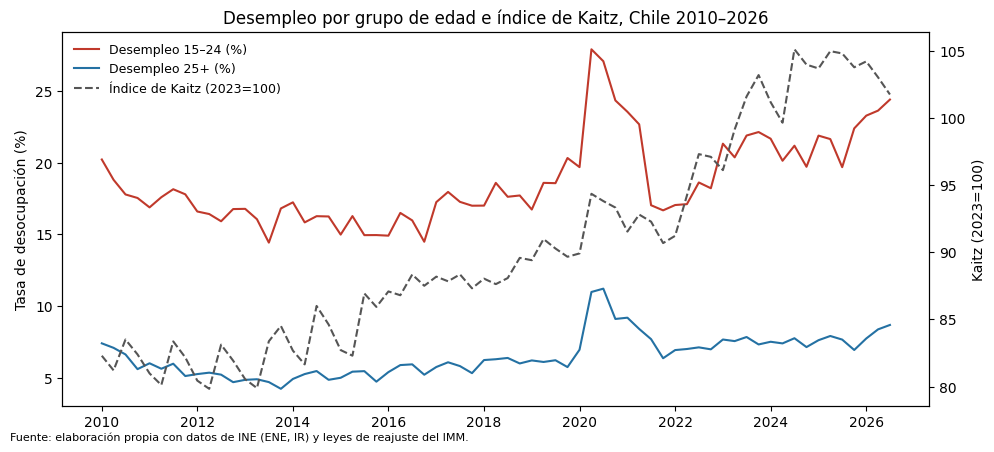

In [13]:
fig, ax1 = plt.subplots(figsize=(10,4.5))
x = pd.PeriodIndex.from_fields(year=base.anio, quarter=base.q, freq='Q').to_timestamp()
ax1.plot(x, base.u_15_24, label='Desempleo 15–24 (%)', color='#c0392b')
ax1.plot(x, base.u_25mas, label='Desempleo 25+ (%)', color='#2471a3')
ax1.set_ylabel('Tasa de desocupación (%)')
ax2 = ax1.twinx()
ax2.plot(x, base.kaitz_idx, label='Índice de Kaitz (2023=100)', color='#555', ls='--')
ax2.set_ylabel('Kaitz (2023=100)')
h1,l1 = ax1.get_legend_handles_labels(); h2,l2 = ax2.get_legend_handles_labels()
ax1.legend(h1+h2, l1+l2, loc='upper left', fontsize=9, frameon=False)
ax1.set_title('Desempleo por grupo de edad e índice de Kaitz, Chile 2010–2026')
fig.text(0.01, 0.01, 'Fuente: elaboración propia con datos de INE (ENE, IR) y leyes de reajuste del IMM.', fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/grafico_series.png', dpi=200); plt.show()

In [14]:
base.to_csv(f"{OUT}/base_trimestral.csv", index=False)
apilada.to_csv(f"{OUT}/base_apilada.csv", index=False)
with pd.ExcelWriter(f"{OUT}/base_datos.xlsx") as w:
    base.to_excel(w, sheet_name='trimestral', index=False)
    apilada.to_excel(w, sheet_name='apilada', index=False)
print("Bases guardadas en", OUT)

Bases guardadas en datos_procesados


---
## Diccionario de variables

| Variable | Descripción | Fuente | Rol en el modelo |
|---|---|---|---|
| `u_15_24`, `u_25mas` | Tasa de desocupación (%) | INE, ENE | Dependiente principal |
| `o_15_24`, `o_25mas` | Tasa de ocupación (%) | INE, ENE | Dependiente (robustez) |
| `p_15_24`, `p_25mas` | Tasa de participación (%) | INE, ENE | Solo descriptiva |
| `u_25_54`, `o_25_54` | Tasas para adultos 25–54 | INE, ENE | Grupo de comparación alternativo (robustez) |
| `imm` | Ingreso Mínimo Mensual, promedio trimestral ($) | Leyes de reajuste | Insumo |
| `ir` | Índice nominal de remuneraciones (2023=100) | INE | Insumo |
| `ln_kaitz` | ln(IMM) − ln(IR) | Elaboración propia | **Explicativa principal** |
| `ln_kaitz_c` | `ln_kaitz` centrado | Elaboración propia | Para la interacción |
| `kaitz_idx` | Kaitz normalizado, promedio 2023 = 100 | Elaboración propia | Gráficos y descriptivos |
| `ln_kaitz_l1`, `ln_kaitz_l2` | Rezagos de 1 y 2 trimestres | Elaboración propia | Robustez |
| `sm_real`, `ln_sm_real` | IMM / IPC × 100 (pesos de 2023) | Leyes, INE | Robustez |
| `inflacion` | IPC, variación 12 meses (%), promedio trimestral | INE / BCCh | Control |
| `imacec_va` | Variación anual del Imacec trimestral (%) | BCCh | **Control del ciclo** |
| `brecha_hp` | Brecha de actividad, filtro HP (%) | Elaboración propia con BCCh | Robustez (opcional) |
| `covid` | 1 entre 2020-T2 y 2021-T2 | Elaboración propia | Control |
| `q1`–`q3` | Dummies trimestrales | Elaboración propia | Control de estacionalidad |
| `tendencia` | Tendencia lineal | Elaboración propia | Control (si el ADF lo indica) |
| `d_joven` | 1 = 15–24, 0 = 25+ | Elaboración propia | Grupo (base apilada) |
| `kaitz_x_joven` | `ln_kaitz_c` × `d_joven` | Elaboración propia | **Prueba de H2** |